In [1]:
import pandas as pd                 # Data tables
import os                           # Returns current directory, create files
import numpy as np                  # Arrays
import matplotlib.pyplot as plt	    # Graphs

from math import sqrt, atan, log, exp, sin, cos, tan, trunc

from scipy.integrate import odeint
from scipy.integrate import solve_ivp
from scipy.optimize import *
from scipy import interpolate

import ipywidgets as widgets
from pathlib import Path

import matplotlib.dates as mdates

from simulation_INTERFACE_261119 import *
from simulation_MATERIALS_261119 import *
from simulation_PREPRO_261119 import *
from simulation_SIM_261119 import *
from simulation_VISUALIZATION_261119 import *
from simulation_WEATHER_261119 import *

pd.options.display.max_columns = 999
np.set_printoptions(threshold=np.inf, linewidth=200)
np.set_printoptions(suppress=True) # avoid scientific notation

# Data

In [2]:
project = 'TVVL_restaurant'

df = pd.read_csv("TVVL_niveau_5_restaurant_components.csv")
wl, wd = read_dataframe(df)

#### General data

In [3]:
# Postal code
CP = 1000

# Internal temperature set point during occupancy
t_set_heating  = 20

# Temperature setpoint during unoccupancy 
t_set_min      = 15 

# Infiltration rate at 50 Pa
n_50 = 1.0

# Windows U-value
U_wd = 1.50  #[W/m2/K]

#### Ventilation

In [4]:
# Occupants requirements
q_occ_m3h  = 45 # Fresh air flow per occupant(m³/h.occ)

# Floor area per occupant
A_fl_occ = 10 # Office value: A supplementary AHU will be added

# Efficiency of ventilation system heat recovery exchanger
epsilon_hx  = 0.80 

#### Hourly schedules

In [5]:
hourly_data = \
[('occupancy',   (0, 0, 0, 0, 0, 0, 0, 0.1, 0.3, 0.7, 0.3, 0.3, 1.0, 1.0, 0.3, 0.7,  0.3, 0.1, 0, 0, 0, 0, 0, 0) ),
 ('ventilation', (0, 0, 0, 0, 0, 0, 0,   1,   1,   1,   1,   1,   1,   1,   1,   1,    1,   1, 0, 0, 0, 0, 0, 0) )
]

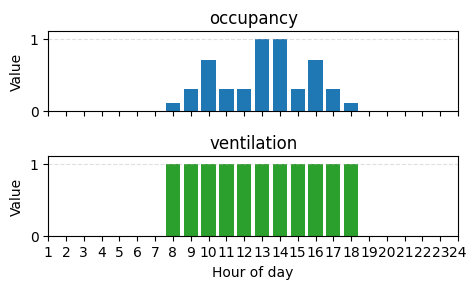

In [6]:
# Create the DataFrame
dfh = pd.DataFrame({name: values for name, values in hourly_data})
dfht= dfh.T

# Rename the columns as strings '1' to '24'
dfht.columns = [str(i) for i in range(1, 25)]

# Prepare subplots
nplots = len(dfht)
colors = ['tab:blue', 'tab:green', 'tab:red', 'tab:blue', 'tab:cyan']
fig, axes = plt.subplots(nplots, 1, figsize=(5, 3), sharex=True)
axes = axes.flatten()     # ensure axes is a flat list

hours = range(1, 25)

# Plot all rows as separate vertical bar plots
for ax, (name, row), color in zip(axes, dfht.iterrows(), colors):
    ax.bar(hours, row.values, color = color)
    ax.set_title(name)
    ax.set_xlim(1, 24)
    ax.set_ylim(0, max(row.values) + 0.1)
    ax.set_ylabel("Value")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

# Add x-axis label only on the last subplot
axes[-1].set_xlabel("Hour of day")
axes[-1].set_xticks(hours)

plt.tight_layout()
plt.show()

#### Control

In [7]:
# Ventilation
CO2_vent_control  = True # Fresh air supply controlled by CO2 probe

# Heating set back
WEEK_END_set_back = True # Unoccupancy and set back of the system during the week-end

# Heating restart
nh_ti_rh = 2.0    # number of reheating hours per °C difference when t_set_heating et t_in
nh_te_rh = 1/6    # number of reheating hours per °C difference when ext temperature < t_e_base

#### Wall types layers

In [8]:
materials_list = []

materials_list.append({"material":'concrete_bloc'      ,"lambda":1.36,"rho":2000,"c":1000})
materials_list.append({"material":'insulation'         ,"lambda":0.026,"rho":80, "c":840})
materials_list.append({"material":'reinforced_concrete',"lambda":2.30,"rho":2400,"c":1000})
materials_list.append({"material":'concrete'           ,"lambda":2.10,"rho":2400,"c":1000})
materials_list.append({"material":'brick'              ,"lambda":1.59,"rho":2200,"c":1000})
materials_list.append({"material":'screed'             ,"lambda":1.40,"rho":2000,"c":1000})
materials_list.append({"material":'foamglass'          ,"lambda":0.055,"rho":150,"c":1000})
materials_list.append({"material":'plaster_panel'      ,"lambda":0.32,"rho":1200,"c":1000})
materials_list.append({"material":'EPS_board'          ,"lambda":0.034,"rho":25, "c":1300})

materials = pd.DataFrame(materials_list)

# Wall layers from indoor to outdoor

wt_layers = \
[('wall_ext', 0, 0.190, 'concrete_bloc'),
 ('wall_ext', 1, 0.100, 'insulation'),
 
 ('wall_sep', 0, 0.190, 'concrete_bloc'),
 
 ('roof'    , 0, 0.300, 'reinforced_concrete'),
 ('roof'    , 1, 0.200, 'insulation'),

 ('floor_sep', 0, 0.060, 'screed'),
 ('floor_sep', 1, 0.065, 'insulation'),
 ('floor_sep', 2, 0.300, 'concrete')
]

 # ('floor_sep, 0, 0.070, 'screed'),
 # ('floor_sep', 1, 0.300, 'concrete')

wt_layers = pd.DataFrame(wt_layers, columns=('wall_type', 'layer', 'thickness', 'material'))
wt_layers = wt_layers.sort_values(['wall_type', 'layer'])
wt_layers = wt_layers.set_index('wall_type')

#### Walls: wall types, environmental temperatures and radiative heating powers

In [9]:
options_w = sorted(set(wt_layers.index)) + ['']
options_t = ['t_ext', 't_min', 't_avg', 't_in', '']

wlv = wl.loc[wl['type'] == 'wall']
get_wlv = env_form(wlv, ['orientation', 'type'], project + '_envsim_wlv.csv', options_w, options_t)

Output()

In [10]:
wlv_filled = wlv.merge(get_wlv(), on=['orientation', 'type'], how='left')

#### Floors and roofs: wall types, environmental temperatures and radiative heating powers

In [11]:
wlh = wl.loc[wl['type'].isin(['floor', 'roof'])]
get_wlh = env_form(wlh, ['type'], project + '_envsim_wvh.csv', options_w, options_t)

Output()

In [12]:
wlh_filled = wlh.merge(get_wlh(), on=['type'], how='left')

#### Panels: wall types, environmental temperatures and radiative heating powers

In [13]:
options_w = sorted(set(wt_layers.index)) + ['no'] + ['']

wlp = wl.loc[wl['type'] == 'panel']
keys_wlp = ['orientation', 'id', 'width_m', 'height_m', 'sill_height_m']
get_wlp = env_form(wlp, keys_wlp, project + '_envsim_wlp.csv', options_w, options_t)

Output()

In [14]:
wlp_filled = wlp.merge(get_wlp(), on=keys_wlp, how='left')

In [15]:
wl_filled = pd.concat([wlv_filled, wlp_filled, wlh_filled])
wl_filled

,id,type,parent,orientation,azimuth_deg,slope_deg,width_m,height_m,sill_height_m,dist_corner_m,area_m2,net_area_m2,wall_type,t_env,rad heating [W/m2]
0,wall_0,wall,NaN,S,0,90,11.899,3.01,0.0,NaN,35.817,1.503,wall_ext,t_ext,0.0
1,wall_1,wall,NaN,E,-90,90,14.796,3.01,0.0,NaN,44.536,38.776,wall_ext,t_ext,0.0
2,wall_2,wall,NaN,N,180,90,11.899,3.01,0.0,NaN,35.817,17.757,wall_ext,t_ext,0.0
3,wall_3,wall,NaN,W,90,90,14.796,3.01,0.0,NaN,44.536,1.192,wall_ext,t_ext,0.0
0,panel_2_0,panel,wall_2,N,180,90,6.000,3.01,0.0,2.293,18.060,NaN,no,t_in,0.0
0,floor,floor,NaN,S,0,0,NaN,NaN,NaN,NaN,176.065,NaN,floor_sep,t_in,100.0
1,roof,roof,NaN,S,0,180,NaN,NaN,NaN,NaN,176.065,NaN,roof,t_ext,0.0


#### Convective heating power

In [16]:
# Installed specific convective heating power (W/m² floor area)
qc_heating  = 10 # W/m²

#### Weather simulation data
'CW' : a cold wave example (1 month)   
'MW'  : a mean January (1 month)

In [17]:
weather = 'CW'

# Simulation

In [18]:
%%time

# df : data
# dfi : intermittent heating results
# dfc : continuous heating results

gen_data  = [CP, t_set_heating, t_set_min, n_50, U_wd, qc_heating]
vent_data = [q_occ_m3h, A_fl_occ, epsilon_hx]
ctrl_data = [CO2_vent_control, WEEK_END_set_back, nh_ti_rh, nh_te_rh] 


df, dfi, dfc = sim(weather, gen_data, vent_data, ctrl_data, dfh, wl_filled, wd, wt_layers, materials)

CPU times: total: 8.66 s
Wall time: 8.77 s


In [19]:
balance = check_balance(dfi, 900)
balance.astype(int)

,heating,ventilation,transmission,thermal mass,unbalance
unit,,,,,
kWh,4060,-208,-3451,-400,0


# Results

#### Energy demands vs Comfort

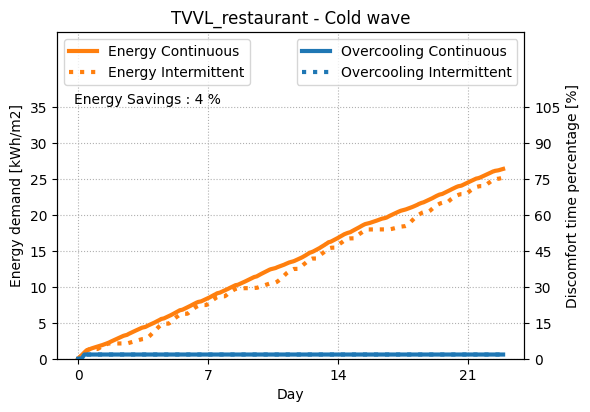

In [20]:
Emax = 35
Estep = 5
pmax = 105 
pstep = 15

# Energy savings
DQ_pct = int(100 * (dfc['Qh_kWhm2'].iloc[-1] - dfi['Qh_kWhm2'].iloc[-1]) / (dfc['Qh_kWhm2'].iloc[-1] + 0.0000001))

fig, ax1 = plt.subplots(figsize=(6, 4))

day = dfi['ts'] / 3600 / 24

ax1.set_xlabel('Day')

ax1.set_ylabel('Energy demand [kWh/m2]', color='k') 
ax1.plot(day, dfc.Qh_kWhm2, color='tab:orange',  linewidth = 3, label = 'Energy Continuous')
ax1.plot(day, dfi.Qh_kWhm2, color='tab:orange',  linewidth = 3, linestyle = 'dotted', \
         label = 'Energy Intermittent')

ax1.set_ylim(0, 1.3 * Emax)
ax1.set_yticks(np.arange(0, Emax + 0.1, step = Estep))
ax1.tick_params(axis='y', labelcolor='k')
ax1.grid(linestyle ='dotted')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
plt.xticks(np.arange(0, int(day.iloc[-1]) + 1, 7))

ax2.set_ylabel('Discomfort time percentage [%]', color='k')
ax2.plot(day, 100 * dfc.fr_overcool, color='tab:blue', linewidth = 3, label = 'Overcooling Continuous')
ax2.plot(day, 100 * dfi.fr_overcool, color='tab:blue', linewidth = 3, linestyle = 'dotted', \
         label = 'Overcooling Intermittent')

ax2.set_ylim(0, 1.3 * pmax)
ax2.set_yticks(np.arange(0, pmax + 0.000001, step = pstep))
ax2.tick_params(axis='y', labelcolor='k')
ax2.legend(loc='upper right')

ax2.text(0.35, 0.77, 'Energy Savings : ' + str(DQ_pct ) + ' %', \
         horizontalalignment='right', verticalalignment='bottom', transform=ax2.transAxes);


fig.tight_layout()  
plt.title( project + ' - ' +  weather_name(weather))
plt.show()

#### Temperature and heating power

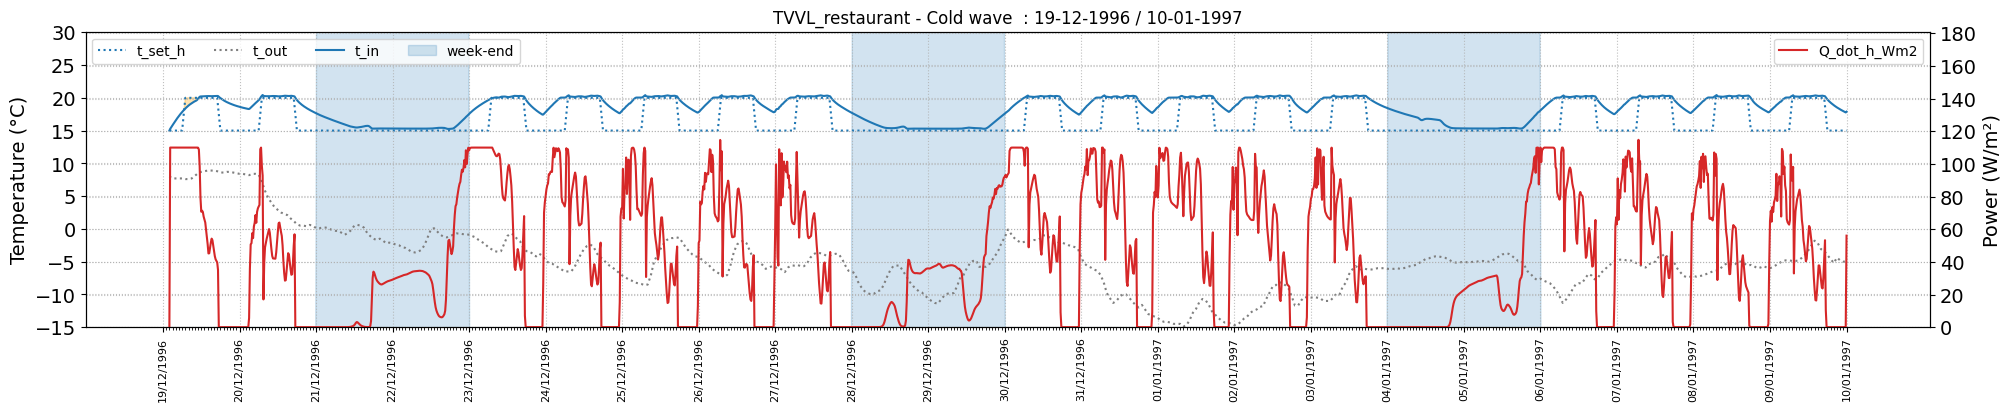

In [21]:
dfr = dfi.copy()

if weather == 'CW' :
    lst_start_plot = ['1996-12-19 00:00:00']
    lst_stop_plot  = ['1997-01-10 00:00:00']

if weather == 'MW' :
    lst_start_plot = ['2005-01-01 00:00:00']
    lst_stop_plot  = ['2005-01-31 00:00:00']
    
for iplot in range(len(lst_start_plot)):
    
    start = pd.to_datetime(lst_start_plot[iplot])
    stop  = pd.to_datetime(lst_stop_plot[iplot]) 
    
    mask = (dfr.index >= start) & (dfr.index <= stop)

    dfr_plot = dfr.loc[mask].copy()
    
    day = dfr_plot.index
    
    fig, ax1 = plt.subplots(figsize=(20, 4), constrained_layout=True)

    # Define temperature and power limits
    T_min, T_max, T_step = (-15, 30.1, 5) if weather != 'HW' else (5, 40.1, 5) 
    Q_min, Q_max, Q_step = (0, 181, 20) 
    
    # Temperature plots
    plot_temperature(ax1, day, dfr_plot, \
                     curves=["t_set_h", "t_out", "t_in"], \
                     colors=['tab:blue',  'tab:grey', 'tab:blue'], \
                     linestyles = ['dotted',   'dotted', 'solid'])
    
    if WEEK_END_set_back:
        ax1.fill_between(day, T_min * np.ones(len(day)), \
                     T_min + (dfr_plot.index.dayofweek >= 5) * (T_max - T_min), \
                     color='tab:blue', alpha=0.2, label = 'week-end' )

    # Fill between t_i and t_set where t_i < t_set
    mask_fill = (dfr_plot["t_in"] < dfr_plot["t_set_h"]) & (dfr_plot["f_occ"] > 0)
    ax1.fill_between(
        day,
        dfr_plot["t_in"],
        dfr_plot["t_set_h"],
        where=mask_fill,
        interpolate=True,
        alpha=0.3,
        color="orange"
    )

    
    ax1.set_ylim(T_min, T_max)
    ax1.set_yticks(np.arange(T_min, T_max, step=T_step))
    ax1.legend(ncol=8, fontsize=10, loc='upper left')
    
    # X-tick configuration
    configure_ticks(ax1, start, stop)
    
    # Power plots (twin axis)
    ax2 = ax1.twinx()
    plot_power(ax2, day, dfr_plot, \
               curves=["Q_dot_h_Wm2"], \
               colors=['tab:red','tab:blue'], \
               linestyles = ['solid', 'solid'], rolling_span = 1)
    
    ax2.set_ylim(Q_min, Q_max)
    ax2.set_yticks(np.arange(Q_min, Q_max, step=Q_step))
    ax2.legend(ncol=5, fontsize=10, loc='upper right')
    
    # Title and display
    plt.title(
        f"{project} - {weather_name(weather)}  : {start.strftime('%d-%m-%Y')} / {stop.strftime('%d-%m-%Y')}"
    )

    plt.grid(linestyle='dotted')
    plt.show()

#### Weekly graph

In [22]:
# ================================================================
# Interactive week selection
# ================================================================

from ipywidgets import interact, IntSlider, Layout

min_week = 0

if weather == 'CW':
    max_week = int(len(df) / (24 * 4 * 7) - 1)
    slider_layout = Layout(width='300px')
    title = 'Cold wave : 19/12/1996 - 10/01/1997'

if weather == 'MW':
    max_week = int(len(df) / (24 * 4 * 7) - 2)
    slider_layout = Layout(width='1000px')
    title = 'Mean January : 01/01/2005 - 31/01/2005'


def interactive_plot(iweek_start):

    # ------------------------------------------------------------
    # Number of 15-minute samples in one week
    # ------------------------------------------------------------
    n_week = 7 * 24 * 4       # 672

    # ------------------------------------------------------------
    # Original row corresponding to the selected week
    # ------------------------------------------------------------
    irow = 2 + 2 * 24 + iweek_start * n_week

    # ------------------------------------------------------------
    # Find the Monday containing this date
    # ------------------------------------------------------------
    start = df.index[irow]

    # Monday 00:00
    start = (
        start
        .normalize()
        - pd.Timedelta(days=start.weekday())
    )

    # Following Monday 00:00
    stop = start + pd.Timedelta(days=7)

    plot_weekly_data(dfr, title, start, stop)


interact(
    interactive_plot,
    iweek_start=IntSlider(
        min=min_week,
        max=max_week,
        step=1,
        value=min_week,
        layout=slider_layout
    )
);

interactive(children=(IntSlider(value=0, description='iweek_start', layout=Layout(width='300px'), max=2), Outp…

#### Daily graph

In [23]:
from ipywidgets import DatePicker, Output
from IPython.display import display, clear_output

import datetime
from datetime import timedelta
from datetime import timezone
from datetime import time

import matplotlib.dates as mdates

if weather == 'CW' :
    min_date = datetime.date(1996, 12, 19)
    max_date = datetime.date(1997,  1, 10)
    title = 'Cold wave : 19/12/1996 - 10/01/1997'

if weather == 'MW' :
    min_date = datetime.date(2004, 9, 1)
    max_date = datetime.date(2005, 6, 10)
    title = 'Mean January : 01/01/2005 - 31/01/2005'


# Create a DatePicker widget
date_picker1 = DatePicker(
    description='Select Date:',
    disabled=False,
    value=min_date,
    min=min_date,
    max=max_date
)

# Create an Output widget to display the plot
output1 = Output()

# Function to generate and display a plot based on the selected date
def on_date_change1(change):
    with output1:
        clear_output(wait=True)  # Clear previous plot
        start_date = change['new']

        start = start_date
        stop = start_date + timedelta(days=1)

        start = pd.to_datetime(start)
        stop = pd.to_datetime(stop)

        plot_daily_data(dfr, title, start, stop)

# Connect the function to the widget's value change
date_picker1.observe(on_date_change1, names='value')

# Display the widget and output
display(date_picker1)
display(output1)

# Trigger initial plot
on_date_change1({'new': date_picker1.value})

DatePicker(value=datetime.date(1996, 12, 19), description='Select Date:', max=datetime.date(1997, 1, 10), min=…

Output()